# 01 · Data cleaning: Tarang Pharma expense claims

**Goal:** turn the raw export into clean, typed tables that the extraction and decision steps can rely on,
**without changing a single raw file**. Everything in `data/raw/` stays byte-for-byte as received;
cleaned copies go to `data/processed/`.

What Sameer (IT) told us about the export (`data/raw/email_thread.txt`):

> *image_file is whatever the app recorded at upload. The older app version saved the full path from the phone,
> and some phones save .jpeg instead of .jpg. A few uploads failed and the photo never reached the server.
> Expense date and amount are typed free-hand by the reps, so the formats are all over the place.
> The app also doesn't fix sideways photos. I haven't cleaned anything.*

This notebook checks each of those claims against the data, finds anything else, fixes what can be fixed safely,
and **flags** (rather than silently fixes) anything that needs a judgement call.

| Step | Issue | Action |
|---|---|---|
| 1 | Load | Read every column as text so nothing is lost (e.g. bill no. `003203` keeps its leading zeros) |
| 2 | Sanity checks | IDs unique, employees known, no stray whitespace |
| 3 | `expense_date` in 3 formats | Parse to ISO `YYYY-MM-DD` after proving the formats are unambiguous |
| 4 | `amount_claimed` in 17 formats | Strip `Rs`/`Rs.`/commas → number |
| 5 | `image_file` paths and `.jpeg` | Map to the actual file on disk; flag the missing photos |
| 6 | `clerk_bill_date` | Parse `DD-MM-YYYY` → ISO |
| 7 | `clerk_gstin` typos | Validate with the official GSTIN checksum; flag, don't fix |
| 8 | Sideways photos | Inspect; leave for the extraction step |
| 9 | Save + final checks | Write `data/processed/`, confirm raw files unchanged |

In [1]:
import hashlib
import re
from collections import Counter
from pathlib import Path

import pandas as pd
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
IMAGES = RAW / "images"
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 60)

## 1 · Load

Every column is read as a string (`dtype=str`, `keep_default_na=False`) so pandas cannot guess types:
blank stays `""` instead of `NaN`, and identifiers such as bill numbers keep their leading zeros.
We also record a checksum of each raw file so we can show at the end that nothing was modified.

In [2]:
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

raw_files = sorted(p for p in RAW.iterdir() if p.is_file())
raw_hashes_before = {p.name: sha256(p) for p in raw_files}

read = lambda name: pd.read_csv(RAW / name, dtype=str, keep_default_na=False)
train_raw = read("claims_train.csv")
test_raw = read("claims_test.csv")
employees = read("employees.csv")

print(f"train: {len(train_raw)} claims | test: {len(test_raw)} claims | employees: {len(employees)}")
print(f"photos on disk: {len(list(IMAGES.glob('*.jpg')))}")
train_raw.head()

train: 283 claims | test: 190 claims | employees: 16
photos on disk: 467


,claim_id,emp_id,submitted_on,expense_date,category,vendor,amount_claimed,rep_comment,image_file,clerk_vendor,clerk_bill_date,clerk_bill_no,clerk_bill_amount,clerk_gstin,status,clerk_note
0,CLM-30412,TPD-0490,2026-06-09,08-06-2026,Food,Highway King Dhaba,330,Dinner on highway,IMG_20260608_080820.jpg,Highway King Dhaba,08-06-2026,1223,330.00,,approved,
1,CLM-30416,TPD-0459,2026-06-09,09/06/26,Food,Hotel Rajdhani Dhaba,325,Dinner on highway,IMG_20260608_211607.jpg,Hotel Rajdhani Dhaba,09-06-2026,3278,325.00,,approved,ok
2,CLM-30418,TPD-0423,2026-06-09,08-06-2026,Lodging,Gulmohar Hotel Executive,Rs 2352,Stay Yavatmal - field work,IMG_20260609_210118.jpg,Hotel Gulmohar Executive,08-06-2026,HGE/26-27/7471,2352.00,27PMLCE5129S3ZO,approved,GST invoice ok
3,CLM-30421,TPD-0452,2026-06-11,10-06-2026,Fuel,Laxmi Auto Fuels,250.00,Fuel,IMG_20260610_101606.jpg,Laxmi Auto Fuels,10-06-2026,003203,240.00,27DPAFU4120X1ZM,approved,
4,CLM-30424,TPD-0503,2026-06-11,11-06-2026,Fuel,Laxmi Auto Fuels,300.00,Petrol two wheeler,IMG-20260610-WA0001.jpg,Laxmi Auto Fuels,11-06-2026,003350,300.00,27DPAFU4120X1ZM,approved,


## 2 · Sanity checks

In [3]:
# Test has no clerk columns; fill them with "" (not NaN) so every column stays text
both = pd.concat([train_raw.assign(split="train"), test_raw.assign(split="test")], ignore_index=True).fillna("")

checks = {
    "duplicate claim_id": both.claim_id.duplicated().sum(),
    "emp_id not in employees.csv": (~both.emp_id.isin(employees.emp_id)).sum(),
    "cells with leading/trailing spaces": sum((both[c] != both[c].str.strip()).sum() for c in test_raw.columns),
    "submitted_on not YYYY-MM-DD": (~both.submitted_on.str.fullmatch(r"\d{4}-\d{2}-\d{2}")).sum(),
}
pd.Series(checks, name="count").to_frame()

,count
duplicate claim_id,0
emp_id not in employees.csv,0
cells with leading/trailing spaces,0
submitted_on not YYYY-MM-DD,0


All zero: the identifiers and `submitted_on` (written by the app, not the rep) are clean.
The problems are in the fields the **reps type by hand** and in `image_file`.

## 3 · `expense_date`: three formats

We replace every digit with `9` to see the shapes of the values.

In [4]:
def shape(value):
    return re.sub(r"[A-Za-z]", "a", re.sub(r"\d", "9", value))

Counter(both.expense_date.map(shape)).most_common()

[('99-99-9999', 275), ('9999-99-99', 153), ('99/99/99', 45)]

Three shapes: `DD-MM-YYYY`, `YYYY-MM-DD` and `DD/MM/YY`. Before parsing, we have to rule out
`MM-DD` order (an American-style date would silently become the wrong date).
If any first part is > 12 it must be a day; if any middle part is > 12 the format is month-first.

In [5]:
dash = both.expense_date[both.expense_date.str.fullmatch(r"\d{2}-\d{2}-\d{4}")]
slash = both.expense_date[both.expense_date.str.contains("/")]

pd.DataFrame({
    "rows": [len(dash), len(slash)],
    "first part > 12 (must be day)": [(dash.str[:2].astype(int) > 12).sum(), (slash.str[:2].astype(int) > 12).sum()],
    "middle part > 12 (would mean month-first)": [(dash.str[3:5].astype(int) > 12).sum(), (slash.str[3:5].astype(int) > 12).sum()],
}, index=["DD-MM-YYYY", "DD/MM/YY"])

,rows,first part > 12 (must be day),middle part > 12 (would mean month-first)
DD-MM-YYYY,275,169,0
DD/MM/YY,45,28,0


**Decision:** both are day-first (many days > 12, no months > 12), so we parse with explicit formats.
A value matching none of them raises an error instead of being guessed.

In [6]:
DATE_FORMATS = {
    r"\d{2}-\d{2}-\d{4}": "%d-%m-%Y",
    r"\d{4}-\d{2}-\d{2}": "%Y-%m-%d",
    r"\d{2}/\d{2}/\d{2}": "%d/%m/%y",
}

def parse_date(value):
    """Parse a rep- or clerk-typed date into a Timestamp. Blank -> NaT. Unknown format -> ValueError."""
    value = value.strip()
    if not value:
        return pd.NaT
    for pattern, fmt in DATE_FORMATS.items():
        if re.fullmatch(pattern, value):
            return pd.to_datetime(value, format=fmt)
    raise ValueError(f"Unrecognised date format: {value!r}")

both["expense_date_clean"] = both.expense_date.map(parse_date)
both[["expense_date", "expense_date_clean"]].drop_duplicates("expense_date").groupby(both.expense_date.map(shape)).head(2)

,expense_date,expense_date_clean
0,08-06-2026,2026-06-08
1,09/06/26,2026-06-09
3,10-06-2026,2026-06-10
6,12/06/26,2026-06-12
16,2026-06-13,2026-06-13
19,2026-06-11,2026-06-11


**Plausibility check:** an expense cannot happen after the claim was submitted.

In [7]:
lag_days = (pd.to_datetime(both.submitted_on) - both.expense_date_clean).dt.days
print("expense after submission:", (lag_days < 0).sum())
lag_days.describe().round(1)

expense after submission: 0


count    473.0
mean       5.8
std        6.8
min        0.0
25%        2.0
50%        5.0
75%        8.0
max       58.0
dtype: float64

No negative lags, so the parsing is consistent. A few claims are submitted more than 30 days later;
that is a **policy** question (late claims), not a data error, so we keep them and leave the decision to the next step.

## 4 · `amount_claimed`: 17 formats

In [8]:
Counter(both.amount_claimed.map(shape)).most_common()

[('999.99', 130),
 ('999', 107),
 ('aa 999', 52),
 ('aa. 999', 40),
 ('9,999.99', 33),
 ('9999', 22),
 ('99.99', 17),
 ('999.9', 14),
 ('aa. 9,999', 12),
 ('99', 10),
 ('aa 9999', 9),
 ('aa. 99', 8),
 ('aa 99', 8),
 ('9999.99', 4),
 ('aa 999.99', 3),
 ('aa 999.9', 3),
 ('9999.9', 1)]

In [9]:
print("prefixes:", Counter(re.match(r"\D*", v).group() for v in both.amount_claimed))

def parse_amount(value):
    """'Rs. 1,234.5' -> 1234.5. Blank -> None. Anything else non-numeric -> ValueError."""
    value = value.strip()
    if not value:
        return None
    cleaned = re.sub(r"^(Rs\.?|INR|₹)\s*", "", value, flags=re.IGNORECASE).replace(",", "")
    if not re.fullmatch(r"\d+(\.\d+)?", cleaned):
        raise ValueError(f"Unrecognised amount: {value!r}")
    return float(cleaned)

both["amount_claimed_clean"] = both.amount_claimed.map(parse_amount)
both[["amount_claimed", "amount_claimed_clean"]].drop_duplicates("amount_claimed").groupby(both.amount_claimed.map(shape)).head(1)

prefixes: Counter({'': 338, 'Rs ': 75, 'Rs. ': 60})


,amount_claimed,amount_claimed_clean
0,330,330.00
2,Rs 2352,2352.00
3,250.00,250.00
8,3680.19,3680.19
11,330.4,330.40
12,3481.8,3481.80
14,"3,539.00",3539.00
18,Rs. 30,30.00
25,Rs. 200,200.00
28,Rs 178,178.00


The only prefixes are `Rs ` and `Rs. `, plus thousands commas. Every value parses.

## 5 · `image_file`: phone paths, `.jpeg`, failed uploads

In [10]:
on_disk = sorted(p.name for p in IMAGES.glob("*.jpg"))
full_path = both.image_file.str.contains(r"[/\\]")
print("rows with a full phone path:", full_path.sum())
print("rows ending .jpeg:", both.image_file.str.lower().str.endswith(".jpeg").sum())
both.loc[full_path, "image_file"].head(3).tolist()

rows with a full phone path: 25
rows ending .jpeg: 8


['/storage/emulated/0/DCIM/Camera/IMG-20260612-WA0058.jpg',
 '/storage/emulated/0/DCIM/Camera/IMG-20260618-WA0208.jpg',
 '/storage/emulated/0/DCIM/Camera/IMG-20260618-WA0030.jpg']

**Decision:** match on the file *stem* (name without folder and extension), case-insensitively.
That handles both quirks in one rule. We checked that no two photos on disk share a stem, so the match is unique.

In [11]:
stem_to_file = {Path(name).stem.lower(): name for name in on_disk}
assert len(stem_to_file) == len(on_disk), "two photos share a stem"

def resolve_image(value):
    """Return the photo's file name in data/raw/images/, or '' if the upload never arrived."""
    stem = Path(value.strip().replace("\\", "/")).stem.lower()
    return stem_to_file.get(stem, "")

both["image_file_clean"] = both.image_file.map(resolve_image)
both["photo_available"] = both.image_file_clean != ""

missing = both[~both.photo_available]
print(f"matched {both.photo_available.sum()} / {len(both)} claims; unused photos on disk: {len(set(on_disk) - set(both.image_file_clean))}")
missing[["split", "claim_id", "image_file", "category", "amount_claimed", "status", "clerk_note"]]

matched 467 / 473 claims; unused photos on disk: 0


,split,claim_id,image_file,category,amount_claimed,status,clerk_note
51,train,CLM-30531,IMG_20260617_212342.jpg,Courier,141.6,queried,bill not attached
128,train,CLM-30710,IMG_20260627_161208.jpg,Parking,30.00,queried,bill not attached
202,train,CLM-30887,IMG-20260706-WA0212.jpg,Courier,141.6,queried,bill not attached
329,test,CLM-31190,IMG_20260724_170809.jpg,Fuel,400,,
368,test,CLM-31280,IMG_20260729_204623.jpg,Food,Rs 330,,
403,test,CLM-31363,IMG_20260802_153908.jpg,Food,Rs 525,,


**6 claims have no photo** (the failed uploads). The 3 training ones were all `queried` by the clerk with
*"bill not attached"*, which confirms these are genuinely missing and not a matching bug.
**Decision:** we keep these rows and set `photo_available = False`. The 3 test claims should go to `review`
(nothing can be read from a photo that doesn't exist).

## 6 · Clerk columns (train only)

In [12]:
train = both[both.split == "train"]
print("clerk_bill_date shapes:", Counter(train.clerk_bill_date.map(shape)))
print("clerk_bill_amount shapes:", Counter(train.clerk_bill_amount.map(shape)))
print("status:", Counter(train.status))
blank_clerk = train.clerk_bill_date == ""
train.loc[blank_clerk, ["claim_id", "photo_available", "status", "clerk_note"]]

clerk_bill_date shapes: Counter({'99-99-9999': 277, '': 6})
clerk_bill_amount shapes: Counter({'999.99': 199, '9999.99': 55, '99.99': 23, '': 6})
status: Counter({'approved': 275, 'queried': 6, 'rejected': 2})


,claim_id,photo_available,status,clerk_note
51,CLM-30531,False,queried,bill not attached
128,CLM-30710,False,queried,bill not attached
188,CLM-30856,True,queried,photo not clear - asked to reupload
201,CLM-30886,True,queried,photo not clear - asked to reupload
202,CLM-30887,False,queried,bill not attached
234,CLM-30979,True,queried,photo not clear - asked to reupload


Clerk dates are a consistent `DD-MM-YYYY` and amounts are plain numbers. The 6 rows with blank clerk fields
are exactly the claims where there was nothing to read (3 missing photos plus 3 *"photo not clear"*), so
blank here means "not transcribed", **not** "zero". We keep them blank, and they must be excluded when we
measure field accuracy.

`clerk_bill_no` stays text: values like `003203` and `HGE/26-27/7471` are identifiers, not numbers.

In [13]:
both["clerk_bill_date_clean"] = both.clerk_bill_date.map(parse_date)
both["clerk_bill_amount_clean"] = both.clerk_bill_amount.map(parse_amount)

## 7 · `clerk_gstin`: the labels themselves have typos

A GSTIN is 15 characters: 2-digit state code, 10-character PAN, entity number, `Z`, and a **check character**
computed from the first 14 (a mod-36 Luhn-style checksum). A clerk typo almost always breaks the checksum.

In [14]:
GSTIN_CHARS = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"
GSTIN_PATTERN = r"\d{2}[A-Z]{5}\d{4}[A-Z][1-9A-Z]Z[0-9A-Z]"

def gstin_is_valid(gstin):
    """True if the GSTIN has the right structure and its check character matches."""
    gstin = gstin.strip().upper()
    if not re.fullmatch(GSTIN_PATTERN, gstin):
        return False
    total = 0
    for i, ch in enumerate(gstin[:14]):
        product = GSTIN_CHARS.index(ch) * (2 if i % 2 else 1)
        total += product // 36 + product % 36
    return GSTIN_CHARS[(36 - total % 36) % 36] == gstin[14]

has_gstin = both.clerk_gstin != ""
both["clerk_gstin_valid"] = pd.Series(pd.NA, index=both.index, dtype="boolean")
both.loc[has_gstin, "clerk_gstin_valid"] = both.loc[has_gstin, "clerk_gstin"].map(gstin_is_valid)

print(both.loc[has_gstin, "clerk_gstin_valid"].value_counts())
both.loc[both.clerk_gstin_valid == False, ["claim_id", "clerk_vendor", "clerk_gstin", "status", "clerk_note"]]

clerk_gstin_valid
True     105
False      7
Name: count, dtype: Int64


,claim_id,clerk_vendor,clerk_gstin,status,clerk_note
11,CLM-30437,Speedlink Couriers,27HJXCW997531ZJ,approved,
28,CLM-30484,Hotel Pradeep Pure Veg,27ODUFJ1Q89K3ZU,approved,
65,CLM-30568,Hotel Pradeep Pure Veg,27ODUFJ178913ZU,approved,verified
107,CLM-30664,Cafe Coffee Corner,27TABPX376MR2Z6,approved,verified
156,CLM-30774,Hotel Krishna Comforts,27H1FCA5856Y3ZE,approved,GST invoice ok
168,CLM-30804,Annapurna Dining Hall,27GIZRL1093Q2ZK,approved,
176,CLM-30824,LAXMI AUTO FUELS,27DPAFU412UX1ZM,approved,


**7 of 112 clerk GSTINs fail the checksum.** We checked one against its photo: for CLM-30437 the Speedlink receipt prints
`27HJXCW9975D1ZJ`, while the clerk typed `27HJXCW997531ZJ` (`5D` read as `53`). Several of these were even marked *verified*.

**Decision:** we do **not** correct them (that would mean guessing), we flag them with `clerk_gstin_valid = False`.
This matters for evaluation: the clerk labels are *not* perfect ground truth, so a model reading the printed GSTIN
correctly would be scored "wrong" on these rows. They should be excluded or re-checked when measuring GSTIN accuracy.
It also gives Nilesh a measured clerk error rate to compare against.

## 8 · Sideways photos

The app doesn't record rotation (there is no EXIF orientation tag on any photo), and width vs height doesn't tell us
the text direction (receipts are photographed on tables at every angle).

EXIF orientation tags: Counter({None: 467})


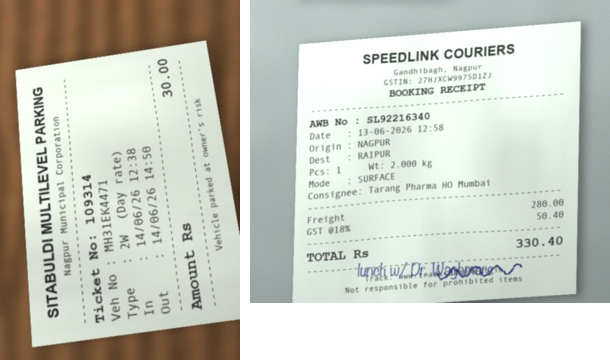

In [15]:
exif_orientation = Counter(Image.open(IMAGES / name).getexif().get(274) for name in on_disk)
print("EXIF orientation tags:", exif_orientation)

sample = ["IMG-20260617-WA0093.jpg", "IMG-20260612-WA0109.jpg"]
thumbs = [Image.open(IMAGES / n).convert("RGB") for n in sample]
for t in thumbs:
    t.thumbnail((360, 360))
canvas = Image.new("RGB", (sum(t.width for t in thumbs) + 10, 360), "white")
x = 0
for t in thumbs:
    canvas.paste(t, (x, 0)); x += t.width + 10
canvas

Left: a parking ticket rotated 90°. Right: an upright courier receipt (note the handwritten *"lunch w/ Dr …"* ink,
which Priya mentioned). **Decision:** the raw photos are left untouched. Orientation has to be detected from the content,
so it belongs to the extraction step (vision models handle rotation; classical OCR will need an orientation pass).

## 9 · Save the cleaned tables

Cleaned columns replace the messy ones; the original text is kept next to them as `*_raw` so every change can be audited.
Dates are written as ISO `YYYY-MM-DD` (the format the submission needs).

In [16]:
def iso(series):
    return series.dt.strftime("%Y-%m-%d").fillna("")

def money(series):
    return series.map(lambda v: "" if pd.isna(v) else f"{v:.2f}")

def build(df, with_clerk):
    out = pd.DataFrame({
        "claim_id": df.claim_id,
        "emp_id": df.emp_id,
        "submitted_on": df.submitted_on,
        "expense_date": iso(df.expense_date_clean),
        "category": df.category,
        "vendor": df.vendor,
        "amount_claimed": money(df.amount_claimed_clean),
        "rep_comment": df.rep_comment,
        "image_file": df.image_file_clean,
        "photo_available": df.photo_available,
    })
    if with_clerk:
        out = out.assign(
            clerk_vendor=df.clerk_vendor,
            clerk_bill_date=iso(df.clerk_bill_date_clean),
            clerk_bill_no=df.clerk_bill_no,
            clerk_bill_amount=money(df.clerk_bill_amount_clean),
            clerk_gstin=df.clerk_gstin,
            clerk_gstin_valid=df.clerk_gstin_valid.astype("object").where(df.clerk_gstin_valid.notna(), ""),
            status=df.status,
            clerk_note=df.clerk_note,
        )
    raw = {"expense_date_raw": df.expense_date, "amount_claimed_raw": df.amount_claimed, "image_file_raw": df.image_file}
    if with_clerk:
        raw["clerk_bill_date_raw"] = df.clerk_bill_date
    return out.assign(**raw).reset_index(drop=True)

train_clean = build(both[both.split == "train"], with_clerk=True)
test_clean = build(both[both.split == "test"], with_clerk=False)

train_clean.to_csv(OUT / "claims_train_clean.csv", index=False)
test_clean.to_csv(OUT / "claims_test_clean.csv", index=False)
print(f"wrote {len(train_clean)} + {len(test_clean)} rows to {OUT.relative_to(ROOT)}/")
train_clean.head()

wrote 283 + 190 rows to data/processed/


,claim_id,emp_id,submitted_on,expense_date,category,vendor,amount_claimed,rep_comment,image_file,photo_available,...,clerk_bill_no,clerk_bill_amount,clerk_gstin,clerk_gstin_valid,status,clerk_note,expense_date_raw,amount_claimed_raw,image_file_raw,clerk_bill_date_raw
0,CLM-30412,TPD-0490,2026-06-09,2026-06-08,Food,Highway King Dhaba,330.00,Dinner on highway,IMG_20260608_080820.jpg,True,...,1223,330.00,,,approved,,08-06-2026,330,IMG_20260608_080820.jpg,08-06-2026
1,CLM-30416,TPD-0459,2026-06-09,2026-06-09,Food,Hotel Rajdhani Dhaba,325.00,Dinner on highway,IMG_20260608_211607.jpg,True,...,3278,325.00,,,approved,ok,09/06/26,325,IMG_20260608_211607.jpg,09-06-2026
2,CLM-30418,TPD-0423,2026-06-09,2026-06-08,Lodging,Gulmohar Hotel Executive,2352.00,Stay Yavatmal - field work,IMG_20260609_210118.jpg,True,...,HGE/26-27/7471,2352.00,27PMLCE5129S3ZO,True,approved,GST invoice ok,08-06-2026,Rs 2352,IMG_20260609_210118.jpg,08-06-2026
3,CLM-30421,TPD-0452,2026-06-11,2026-06-10,Fuel,Laxmi Auto Fuels,250.00,Fuel,IMG_20260610_101606.jpg,True,...,003203,240.00,27DPAFU4120X1ZM,True,approved,,10-06-2026,250.00,IMG_20260610_101606.jpg,10-06-2026
4,CLM-30424,TPD-0503,2026-06-11,2026-06-11,Fuel,Laxmi Auto Fuels,300.00,Petrol two wheeler,IMG-20260610-WA0001.jpg,True,...,003350,300.00,27DPAFU4120X1ZM,True,approved,,11-06-2026,300.00,IMG-20260610-WA0001.jpg,11-06-2026


## Final checks

In [17]:
assert len(train_clean) == len(train_raw) and len(test_clean) == len(test_raw), "row count changed"
assert (train_clean.claim_id.values == train_raw.claim_id.values).all(), "row order changed"
assert {sha256(p) for p in raw_files} == set(raw_hashes_before.values()), "a raw file was modified"
assert (both.expense_date_clean.notna()).all() and both.amount_claimed_clean.notna().all()

summary = {
    "claims (train / test)": f"{len(train_clean)} / {len(test_clean)}",
    "expense_date reformatted to ISO": int((both.expense_date != iso(both.expense_date_clean)).sum()),
    "amount_claimed had Rs/commas": int((~both.amount_claimed.str.fullmatch(r"[\d.]+")).sum()),
    "image_file resolved (path or .jpeg)": int((both.image_file != both.image_file_clean).sum() - (~both.photo_available).sum()),
    "photo missing (train / test)": f"{(~train_clean.photo_available).sum()} / {(~test_clean.photo_available).sum()}",
    "clerk fields blank (no readable photo)": int((train_clean.clerk_bill_date == "").sum()),
    "clerk GSTIN fails checksum": int((train_clean.clerk_gstin_valid == False).sum()),
    "raw files modified": 0,
}
pd.Series(summary, name="value").to_frame()

,value
claims (train / test),283 / 190
expense_date reformatted to ISO,320
amount_claimed had Rs/commas,168
image_file resolved (path or .jpeg),33
photo missing (train / test),3 / 3
clerk fields blank (no readable photo),6
clerk GSTIN fails checksum,7
raw files modified,0


## Summary

* Raw data untouched; cleaned tables are in `data/processed/claims_{train,test}_clean.csv`.
* **Fixed (mechanical, no judgement):** date formats, `Rs`/comma amounts, phone paths, and `.jpeg` file names.
* **Flagged (judgement needed downstream):**
  * `photo_available = False` for 6 claims; the 3 test claims should be sent to review.
  * `clerk_gstin_valid = False` for 7 clerk labels: label noise to exclude when scoring GSTIN accuracy.
  * Blank clerk fields on 6 training rows: not transcribed, so exclude from accuracy.
* **Left for later steps:** rotated photos (extraction), handwriting on bills, late submissions, and duplicate bills (decision logic).

The same logic is packaged as `src/tarang/cleaning.py` and runs end-to-end with `python scripts/clean_data.py`.